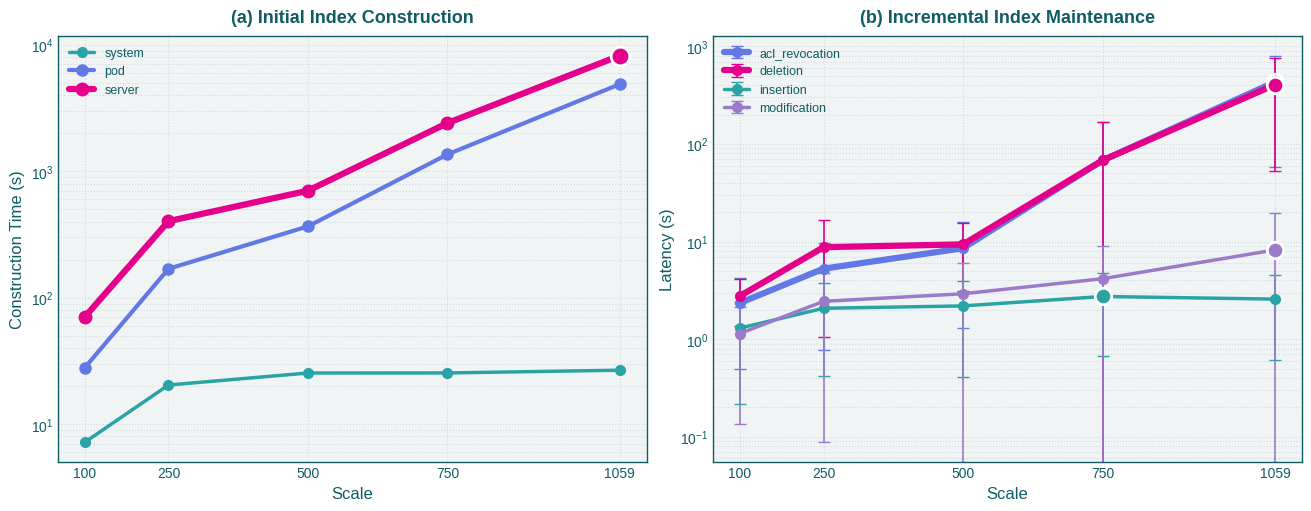

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# DATA: INITIAL CONSTRUCTION
# ============================================================

construction = pd.DataFrame({
    "scale": [100, 250, 500, 750, 1059],
    "system": [7.20, 20.41, 25.40, 25.43, 26.73],
    "pod": [28.00, 169.38, 366.70, 1359.67, 4883.90],
    "server": [70.56, 403.08, 702.17, 2404.28, 8222.68]
})

# ============================================================
# LOAD MAINTENANCE RESULTS
# ============================================================

df = pd.read_csv("results.csv")

df = df[
    (df["level"] == "total")
    &
    (df["operation"].isin([
        "insertion",
        "deletion",
        "modification",
        "acl_revocation"
    ]))
].copy()

maintenance = (
    df.groupby(["scale", "operation"])["wall_seconds"]
    .agg(
        mean="mean",
        std="std"
    )
    .reset_index()
)

maintenance["std"] = maintenance["std"].fillna(0)

# ============================================================
# COLORS (matching your paper figures)
# ============================================================

TEXT_COLOR = "#0F5C63"

COLORS = {

    # construction
    "system": "#2AA3A5",
    "pod": "#6278E5",
    "server": "#E4008A",

    # maintenance
    "insertion": "#2AA3A5",
    "acl_revocation": "#6278E5",
    "deletion": "#E4008A",
    "modification": "#9B7BC9"
}

# ============================================================
# STYLE
# ============================================================

plt.style.use("seaborn-v0_8-whitegrid")

plt.rcParams.update({

    "font.family": "sans-serif",

    "font.size": 11,

    "axes.labelsize": 12,
    "axes.titlesize": 13,

    "legend.fontsize": 9,

    "xtick.labelsize": 10,
    "ytick.labelsize": 10,

    "text.color": TEXT_COLOR,
    "axes.labelcolor": TEXT_COLOR,
    "axes.edgecolor": TEXT_COLOR,
    "axes.titlecolor": TEXT_COLOR,
    "xtick.color": TEXT_COLOR,
    "ytick.color": TEXT_COLOR,

    "pdf.fonttype": 42,
    "ps.fonttype": 42
})

# ============================================================
# FIGURE
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 5),   # taller figure
    constrained_layout=True
)

for ax in axes:
    ax.set_facecolor("#F1F4F5")

# ============================================================
# (a) INITIAL INDEX CONSTRUCTION
# ============================================================

ax = axes[0]

ax.plot(
    construction["scale"],
    construction["system"],
    color=COLORS["system"],
    marker="o",
    markersize=7,
    linewidth=2.5,
    label="system"
)

ax.plot(
    construction["scale"],
    construction["pod"],
    color=COLORS["pod"],
    marker="o",
    markersize=8,
    linewidth=3.0,
    label="pod"
)

ax.plot(
    construction["scale"],
    construction["server"],
    color=COLORS["server"],
    marker="o",
    markersize=9,
    linewidth=4.5,
    label="server"
)

# highlight final point

ax.scatter(
    1059,
    8222.68,
    s=180,
    color=COLORS["server"],
    edgecolor="white",
    linewidth=2,
    zorder=10
)

ax.set_yscale("log")

ax.set_title(
    "(a) Initial Index Construction",
    fontsize=13,
    fontweight="bold",
    color=TEXT_COLOR,
    pad=10
)

ax.set_xlabel("Scale")
ax.set_ylabel("Construction Time (s)")

ax.set_xticks([100, 250, 500, 750, 1059])

ax.grid(
    True,
    which="both",
    linestyle=":",
    linewidth=0.8,
    color="#C9D5D8",
    alpha=0.8
)

# INSIDE PLOT

ax.legend(
    loc="upper left",
    frameon=False
)

# ============================================================
# (b) INCREMENTAL MAINTENANCE
# ============================================================

ax = axes[1]

operations = [
    ("acl_revocation", "acl_revocation"),
    ("deletion", "deletion"),
    ("insertion", "insertion"),
    ("modification", "modification")
]

for operation, label in operations:

    subset = (
        maintenance[
            maintenance["operation"] == operation
        ]
        .sort_values("scale")
    )

    if subset.empty:
        continue

    linewidth = (
        4.5
        if operation in [
            "acl_revocation",
            "deletion"
        ]
        else 2.5
    )

    ax.errorbar(
        subset["scale"],
        subset["mean"],
        yerr=subset["std"],
        color=COLORS[operation],
        marker="o",
        markersize=7,
        linewidth=linewidth,
        capsize=4,
        elinewidth=1.2,
        label=label
    )

    max_row = subset.loc[
        subset["mean"].idxmax()
    ]

    ax.scatter(
        max_row["scale"],
        max_row["mean"],
        s=140,
        color=COLORS[operation],
        edgecolor="white",
        linewidth=2,
        zorder=10
    )

ax.set_yscale("log")

ax.set_title(
    "(b) Incremental Index Maintenance",
    fontsize=13,
    fontweight="bold",
    color=TEXT_COLOR,
    pad=10
)

ax.set_xlabel("Scale")
ax.set_ylabel("Latency (s)")

ax.set_xticks([100, 250, 500, 750, 1059])

ax.grid(
    True,
    which="both",
    linestyle=":",
    linewidth=0.8,
    color="#C9D5D8",
    alpha=0.8
)

# INSIDE PLOT

ax.legend(
    loc="upper left",
    frameon=False
)

# ============================================================
# SAVE
# ============================================================

plt.savefig(
    "incremental_index_evaluation.pdf",
    bbox_inches="tight"
)

plt.savefig(
    "incremental_index_evaluation.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()